In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

daily_all = pd.read_csv('daily_allyears.csv', parse_dates=['date'], index_col='date')
open_days = daily_all[~daily_all["closed"]]

train = open_days[open_days["year"] == 2024]
valid = open_days[open_days["year"] == 2025]
test  = open_days[open_days["year"] == 2026]
print(train.shape, valid.shape, test.shape)

(366, 8) (364, 8) (303, 8)


In [2]:
def scores(y_true, log_pred):
    rmse_log = np.sqrt(np.mean((np.log(y_true) - log_pred) ** 2))
    mae = np.mean(np.abs(y_true - np.exp(log_pred)))
    return round(rmse_log, 3), round(mae, 0)

# 1) Naive: every day = 2024 mean (on log scale)
naive_pred = np.full(len(valid), np.log(train["ride_count"]).mean())
print("Naive      :", scores(valid["ride_count"], naive_pred))

# 2) OLS Model 2, trained on 2024 only
formula = "np.log(ride_count) ~ C(season) * C(day_type) + temp_mean + precip_mm + is_holiday"
ols_2024 = smf.ols(formula, data=train).fit()
ols_pred = ols_2024.predict(valid)
print("OLS Model 2:", scores(valid["ride_count"], ols_pred))

Naive      : (np.float64(1.088), np.float64(1997.0))
OLS Model 2: (np.float64(0.419), np.float64(894.0))


In [3]:
from sklearn.tree import DecisionTreeRegressor

features = ["season", "day_type", "temp_mean", "precip_mm", "is_holiday"]

def make_X(df):
    return pd.get_dummies(df[features], columns=["season", "day_type"], dtype=int)

X_train, X_valid = make_X(train), make_X(valid)
y_train = np.log(train["ride_count"])

for depth in [2, 3, 4, 5, 6, 8, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_train, y_train)
    print(depth, "| train:", scores(train["ride_count"], tree.predict(X_train)),
                 "| valid:", scores(valid["ride_count"], tree.predict(X_valid)))

2 | train: (np.float64(0.644), np.float64(1007.0)) | valid: (np.float64(0.569), np.float64(937.0))
3 | train: (np.float64(0.565), np.float64(890.0)) | valid: (np.float64(0.518), np.float64(805.0))
4 | train: (np.float64(0.482), np.float64(736.0)) | valid: (np.float64(0.501), np.float64(762.0))
5 | train: (np.float64(0.41), np.float64(632.0)) | valid: (np.float64(0.457), np.float64(715.0))
6 | train: (np.float64(0.342), np.float64(485.0)) | valid: (np.float64(0.452), np.float64(638.0))
8 | train: (np.float64(0.254), np.float64(325.0)) | valid: (np.float64(0.494), np.float64(729.0))
None | train: (np.float64(0.04), np.float64(15.0)) | valid: (np.float64(0.543), np.float64(864.0))


### Regression tree: choosing the depth (train 2024, validate 2025)

| max_depth | Train RMSE (log) | **Valid RMSE (log)** | Train MAE (rides) | **Valid MAE (rides)** |
|---|---|---|---|---|
| 2 | 0.644 | 0.569 | 1007 | 937 |
| 3 | 0.565 | 0.518 | 890 | 805 |
| 4 | 0.482 | 0.501 | 736 | 762 |
| 5 | 0.410 | 0.457 | 632 | 715 |
| **6** | 0.342 | **0.452** | 485 | **638** |
| 8 | 0.254 | 0.494 | 325 | 729 |
| None | 0.040 | 0.543 | 15 | 864 |
| *OLS Model 2 (reference)* | | *0.419* | | *894* |

**Interpretation**

- **Underfitting (depth 2–3):** the tree is too simple. Training and validation errors are both high.
- **Best depth = 6:** it gives the lowest validation error on both metrics. The depth is chosen on the validation set, never on the training set, because the training error always falls as the tree grows.
- **Overfitting (depth 8 and None):** the training error keeps falling, and with unlimited depth it is almost zero (MAE 15 rides). The validation error rises again (0.543 / 864). The unlimited tree memorises day-specific noise in 2024 that does not repeat in 2025. The widening gap between training and validation error is the bias–variance trade-off.

**Tree (depth 6) vs OLS Model 2**

- **MAE:** the tree wins (638 vs 894 rides per day). MAE is measured in rides, so it is dominated by high-count summer days. OLS assumes a straight-line temperature effect and over-predicts very hot days (saturation, see the Model 2 residuals). The tree's step-wise predictions stop rising and capture this.
- **RMSE on the log scale:** OLS wins (0.419 vs 0.452). Log errors are relative (percentage) errors, so they are dominated by low-count winter days. A tree gives every day in a leaf the same prediction, which is coarse when counts are small. The smooth temperature effect in OLS is more precise there.
- So neither model is better on every metric. The choice of metric decides the "winner", which is why both are reported.

**Caveat:** because the depth was tuned on 2025, the validation scores of the tree are slightly optimistic. The honest comparison is the final test on 2026, which is used only once (step 6.6).

In [4]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=500, max_features="sqrt", random_state=0, n_jobs=-1)
rf.fit(X_train, y_train)

print("RF train:", scores(train["ride_count"], rf.predict(X_train)))
print("RF valid:", scores(valid["ride_count"], rf.predict(X_valid)))

importance = pd.Series(rf.feature_importances_, index=X_train.columns)
print(importance.sort_values(ascending=False).round(3))

RF train: (np.float64(0.19), np.float64(266.0))
RF valid: (np.float64(0.415), np.float64(596.0))
temp_mean           0.433
season_Winter       0.294
precip_mm           0.082
season_Summer       0.052
season_Autumn       0.042
day_type_Weekend    0.029
day_type_Weekday    0.027
season_Spring       0.024
is_holiday          0.019
dtype: float64


### Random forest (train 2024, validate 2025)

| Model | Train RMSE (log) | **Valid RMSE (log)** | Train MAE (rides) | **Valid MAE (rides)** |
|---|---|---|---|---|
| Naive (2024 mean) | | 1.088 | | 1997 |
| OLS Model 2 | | 0.419 | | 894 |
| Tree (depth 6) | 0.342 | 0.452 | 485 | 638 |
| **Random forest** | 0.190 | **0.415** | 266 | **596** |

**Interpretation**

- **Training error:** the forest's trees are grown to unlimited depth, but its training error (0.190) is much higher than that of the single unlimited tree (0.040). Each tree is trained on a bootstrap sample and never sees about one third of the days. Averaging 500 such trees smooths out what individual trees memorised. This is how the forest reduces variance.
- **Validation:** the forest beats OLS on both metrics. The MAE gain is large (596 vs 894 rides per day, about one third lower), while the gain in log RMSE is negligible (0.415 vs 0.419). The forest keeps the single tree's advantage on hot summer days (saturation) and, because averaging smooths the tree's steps, it no longer loses on low-count winter days.
- **No tuning:** the settings (500 trees, `max_features="sqrt"`) were fixed in advance and not chosen on 2025, so this validation score is not optimistic, unlike the tuned tree.

**Feature importance**

- **Temperature is the most important feature (0.433)**, consistent with Model 2, where weather explained most of the season effect.
- **Winter ranks second (0.294)** partly because it acts as a proxy for cold weather. At each split only 3 of the 9 columns are candidates, so when `temp_mean` is not among them the tree splits on Winter instead. Importance is shared between correlated features.
- **Holiday has low importance (0.019)** because there are only about 12 holidays per year, so it is rarely used in a split. This does not mean holidays have no effect (Model 2 estimated about −55%).
- Importance shows what the model relies on for prediction. It does not show cause and effect.

In [5]:
from sklearn.ensemble import GradientBoostingRegressor

for n in [50, 100, 200, 300, 500, 1000]:
    gb = GradientBoostingRegressor(n_estimators=n, learning_rate=0.05, max_depth=3, random_state=0)
    gb.fit(X_train, y_train)
    print(n, "| train:", scores(train["ride_count"], gb.predict(X_train)),
             "| valid:", scores(valid["ride_count"], gb.predict(X_valid)))

50 | train: (np.float64(0.406), np.float64(716.0)) | valid: (np.float64(0.378), np.float64(589.0))
100 | train: (np.float64(0.339), np.float64(549.0)) | valid: (np.float64(0.381), np.float64(548.0))
200 | train: (np.float64(0.295), np.float64(481.0)) | valid: (np.float64(0.396), np.float64(570.0))
300 | train: (np.float64(0.262), np.float64(431.0)) | valid: (np.float64(0.404), np.float64(576.0))
500 | train: (np.float64(0.212), np.float64(356.0)) | valid: (np.float64(0.414), np.float64(583.0))
1000 | train: (np.float64(0.144), np.float64(253.0)) | valid: (np.float64(0.447), np.float64(620.0))


### Boosting: how many rounds?

Boosting adds small trees one after another, and each new tree tries to fix the mistakes of the ones before it.

- The training error goes down with every round (0.406 → 0.144).
- The validation error goes down at first, then goes up again after about 100 rounds (0.447 at 1000). After that point the model starts to memorise 2024, the same thing we saw with tree depth.
- I picked **100 rounds**: it has the best MAE (548) and almost the best log RMSE (0.381 vs 0.378 at 50).
- At 50 rounds the validation error is lower than the training error. 2024 had more unusual low days (March, Christmas Eve), so it is a harder year to fit.

**So far on 2025:** boosting is the best on both metrics (0.381 / 548), ahead of the random forest (0.415 / 596) and OLS (0.419 / 894). But I chose the number of rounds by looking at 2025, so this score is a bit too good. The 2026 test will show the real ranking.

In [6]:
full = pd.concat([train, valid])
X_full, X_test = make_X(full), make_X(test)
y_full = np.log(full["ride_count"])

models = {
    "Tree (depth 6)": DecisionTreeRegressor(max_depth=6, random_state=0),
    "Random forest": RandomForestRegressor(n_estimators=500, max_features="sqrt", random_state=0, n_jobs=-1),
    "Boosting (100)": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=0),
}

results = {}
results["Naive"] = scores(test["ride_count"], np.full(len(test), y_full.mean()))
results["OLS Model 2"] = scores(test["ride_count"], smf.ols(formula, data=full).fit().predict(test))

for name, model in models.items():
    model.fit(X_full, y_full)
    results[name] = scores(test["ride_count"], model.predict(X_test))

pd.DataFrame(results, index=["RMSE log", "MAE"]).T

,RMSE log,MAE
Naive,1.224,2514.0
OLS Model 2,0.385,751.0
Tree (depth 6),0.375,639.0
Random forest,0.333,602.0
Boosting (100),0.314,595.0


### Final test on 2026

I trained all models again on 2024 + 2025 (730 days) and tested them **once** on 2026 (Jan–Oct, 303 days). I didn't choose anything by looking at 2026, so these are the honest scores.

- **Boosting is the best** (0.314 / 595), and the random forest is almost the same (0.333 / 602). The ranking is the same as on 2025.
- Boosting makes about **21% less error than OLS** (595 vs 751 rides per day) and about **76% less than the naive guess** (2514).
- Log RMSE got better for every model, because they learned from two years instead of one. MAE went up a little because 2026 has no November or December, so the average day has more rides.

**Keep in mind:**
- I used the real measured weather for 2026. A real forecast would have to use a weather forecast, so the errors would be a bit bigger.
- 2026 is not a full year.

**OLS or boosting?** They do different jobs. OLS explains: its coefficients tell how much temperature, rain or a holiday changes the rides. Boosting and the random forest predict better, but they don't give simple numbers like that. So I use OLS to answer my research question and the tree models for prediction.

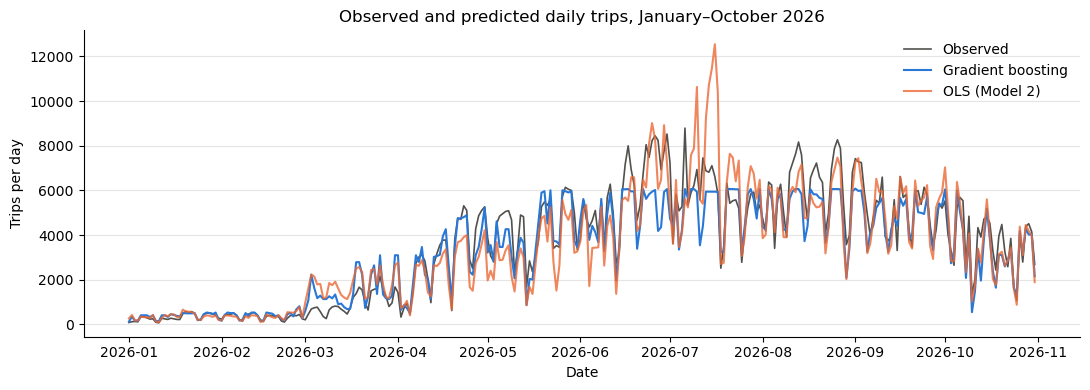

In [7]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

best = models["Boosting (100)"]
ols_full = smf.ols(formula, data=full).fit()

plot_df = pd.DataFrame({
    "Observed": test["ride_count"],
    "Boosting": np.exp(best.predict(X_test)),
    "OLS": np.exp(ols_full.predict(test)),
})

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(plot_df.index, plot_df["Observed"], color="#52514e", linewidth=1.2, label="Observed")
ax.plot(plot_df.index, plot_df["Boosting"], color="#2a78d6", linewidth=1.5, label="Gradient boosting")
ax.plot(plot_df.index, plot_df["OLS"], color="#eb6834", linewidth=1.5, alpha=0.8, label="OLS (Model 2)")
ax.set(title="Observed and predicted daily trips, January–October 2026", xlabel="Date", ylabel="Trips per day")
ax.grid(axis="y", color="#e5e5e5")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/fig6_test_2026.png", dpi=200)
plt.show()

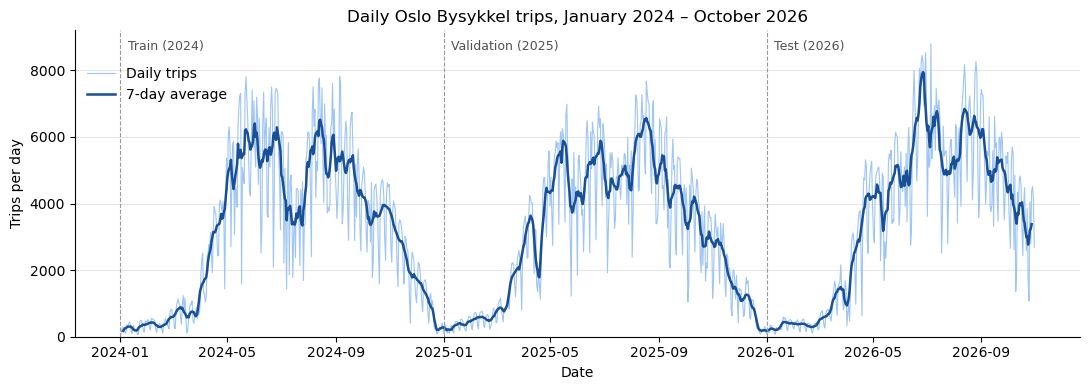

In [8]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

plot_days = daily_all[~daily_all["closed"]]
weekly = plot_days["ride_count"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(plot_days.index, plot_days["ride_count"], color="#9ec5f4", linewidth=0.8, label="Daily trips")
ax.plot(weekly.index, weekly, color="#184f95", linewidth=1.8, label="7-day average")

for start, name in [("2024-01-01", "Train (2024)"), ("2025-01-01", "Validation (2025)"), ("2026-01-01", "Test (2026)")]:
    ax.axvline(pd.Timestamp(start), color="#999999", linewidth=0.8, linestyle="--")
    ax.text(pd.Timestamp(start) + pd.Timedelta(days=8), 8600, name, fontsize=9, color="#52514e")

ax.set(title="Daily Oslo Bysykkel trips, January 2024 – October 2026", xlabel="Date", ylabel="Trips per day")
ax.set_ylim(0, 9200)
ax.grid(axis="y", color="#e5e5e5")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.92))
plt.tight_layout()
plt.savefig("figures/fig1_daily_trips.png", dpi=200)
plt.show()